<a href="https://colab.research.google.com/github/Irinejeba/DL-Class/blob/main/Real_dataset_ANN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **ANN Regression(Predict prices using ANN: California Housing dataset)**

**Import Libraries**

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


**Load the dataset**

In [8]:

# Load California Housing dataset
data = fetch_california_housing()

X = data.data
y = data.target

print("Input shape:", X.shape)
print("Output shape:", y.shape)
print("Features:", data.feature_names)


Input shape: (20640, 8)
Output shape: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Split the dataset**

In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)


(16512, 8)
(4128, 8)


**Feature Scaling**

In [10]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


**Build ANN Model**

In [11]:

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

**Compile model**

In [12]:

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)


**Train the model**

In [13]:

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.8168 - mae: 0.6113 - val_loss: 0.4695 - val_mae: 0.4981
Epoch 2/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4061 - mae: 0.4579 - val_loss: 0.4189 - val_mae: 0.4751
Epoch 3/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3779 - mae: 0.4402 - val_loss: 0.3918 - val_mae: 0.4434
Epoch 4/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3591 - mae: 0.4268 - val_loss: 0.3928 - val_mae: 0.4424
Epoch 5/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3586 - mae: 0.4207 - val_loss: 0.5227 - val_mae: 0.4572
Epoch 6/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3482 - mae: 0.4146 - val_loss: 0.4056 - val_mae: 0.4236
Epoch 7/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.3571 - mae: 0.4129 - val_loss: 0.3852 - val_mae: 0.4257
Epoch 8/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3538 - mae: 0.4051 - val_loss: 0.3464 - val_mae: 0.4120
Epoch 9/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

**Evaluate model**

In [14]:

loss, mae = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test MAE:", mae)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3097 - mae: 0.3873
Test Loss: 0.3097389042377472
Test MAE: 0.38731878995895386


**Predict House prices**

In [15]:

predictions = model.predict(X_test)

for i in range(5):
    print("Actual:", y_test[i])
    print("Predicted:", predictions[i][0])
    print()


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Actual: 0.477
Predicted: 0.5297052

Actual: 0.458
Predicted: 1.1741441

Actual: 5.00001
Predicted: 4.772255

Actual: 2.186
Predicted: 2.7399218

Actual: 2.78
Predicted: 3.1728182



**Plot training loss**

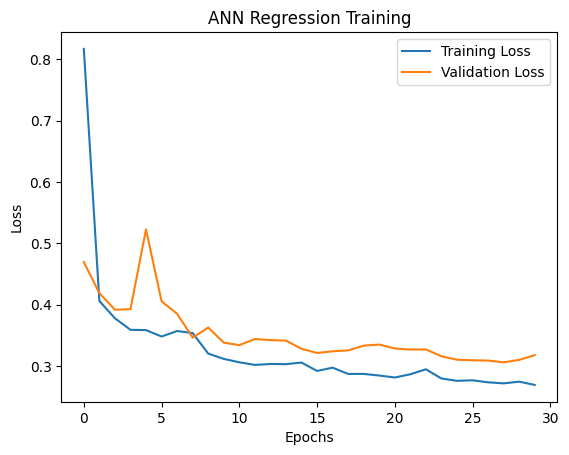

In [17]:

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('ANN Regression Training')
plt.legend()
plt.show()


### **ANN Classification (Predict whether a brest tumour is benign or malignant-Breast cancer dataset)**

**Import Libraries**

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


**Load dataset**

In [19]:

data = load_breast_cancer()

X = data.data
y = data.target

print("Input shape:", X.shape)
print("Output shape:", y.shape)
print("Target names:", data.target_names)


Input shape: (569, 30)
Output shape: (569,)
Target names: ['malignant' 'benign']


**Split dataset**

In [20]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


**Feature Scaling**

In [21]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


**Bulid ANN model**

In [22]:

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

**Compile model**

In [23]:

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


**Train Model**

In [24]:

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.8901 - loss: 0.4284 - val_accuracy: 0.9341 - val_loss: 0.3054
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9753 - loss: 0.2521 - val_accuracy: 0.9780 - val_loss: 0.1938
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9725 - loss: 0.1591 - val_accuracy: 0.9780 - val_loss: 0.1333
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9753 - loss: 0.1140 - val_accuracy: 0.9780 - val_loss: 0.1030
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9780 - loss: 0.0913 - val_accuracy: 0.9780 - val_loss: 0.0858
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.9863 - loss: 0.0796 - val_accuracy: 0.9890 - val_loss: 0.0728
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9918 - loss: 0.0708 - val_accuracy: 0.9890 - val_loss: 0.0652
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9918 - loss: 0.0649 - val_accuracy: 0.9890 - v

**Evaluate Model**

In [25]:

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9737 - loss: 0.1044
Test Loss: 0.10443011671304703
Test Accuracy: 0.9736841917037964


**Make Predictions**

In [26]:

y_pred = model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int).flatten()

print("Actual:", y_test[:10])
print("Predicted:", y_pred[:10])


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Actual: [0 1 0 1 0 1 1 0 0 0]
Predicted: [0 1 0 0 0 1 1 0 0 0]


**Classification Report**

In [27]:

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


Accuracy: 0.9736842105263158

Confusion Matrix:
[[41  1]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



**Plot Summary**

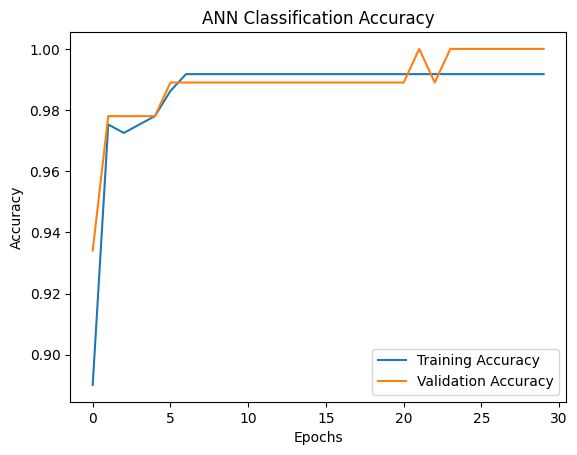

In [28]:

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ANN Classification Accuracy')
plt.legend()
plt.show()
